# TinyStories × Masked Diffusion Language Model (MDLM)
### HW2 Problem 2 | Student TODO Notebook (25% Implementation)


**Student ID:** 315511079

**Run on one Google Colab T4 GPU** (Runtime → Change runtime type → T4 GPU), *not* A100: the assignment
restricts Problem 2 to one T4 within a 4-hour GPU budget. Run all cells top-to-bottom once.

Adjustments to the provided notebook (all stated here for reproducibility):
* `TRAIN_STORIES = 120_000` to match the assignment's 120,000-story training subset (the template had 300,000).
* `BATCH_SIZE = 64` (the template's 4 was tuned for a 12 GB RTX 3060; 64 uses the T4 far more efficiently). Learning rate, optimizer, model and tokenizer are unchanged.
* Training length is set by epochs (`NUM_EPOCHS = 20`) instead of wall-clock time; `TRAIN_MINUTES = 200` remains only as a safety cap so the run never exceeds the 4-hour T4 budget.
* A held-out validation-loss probe (fixed seed, every `EVAL_EVERY` steps) was added to the loop to check overfitting; it never updates weights.


## 1. GPU setting

In [1]:
%pip -q install "datasets>=3.0,<5" "tokenizers>=0.20,<1"

import torch
assert torch.cuda.is_available(), "請先在 Colab 啟用 GPU (Runtime → Change runtime type → T4)"
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.11.0+cu130


## 2. Imports



In [2]:

import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
assert torch.cuda.is_available(), "CUDA GPU not found!"
DEVICE = torch.device("cuda")

# Dataset
TRAIN_STORIES = 120_000  # assignment: provided subset of 120,000 training stories
VALID_STORIES = 1_000
TOKENIZER_TRAIN_STORIES = 20_000

# Model / Training configuration
VOCAB_TARGET = 8_000
SEQ_LEN = 128
BATCH_SIZE = 64  # Colab T4 16GB (template value 4 was for an RTX 3060 12GB)

# Local output paths
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / "tiny_mdlm_v2.pt"
TOKENIZER_PATH = OUTPUT_DIR / "tiny_mdlm_v2_tokenizer.json"

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", CHECKPOINT_PATH.resolve())
print("Tokenizer:", TOKENIZER_PATH.resolve())


Device: cuda
GPU: Tesla T4
Checkpoint: /content/outputs/tiny_mdlm_v2.pt
Tokenizer: /content/outputs/tiny_mdlm_v2_tokenizer.json


## 3. Dateset：TinyStories



In [3]:
dataset_name = "roneneldan/TinyStories"

train_stream = load_dataset(dataset_name, split="train", streaming=True)
valid_stream = load_dataset(dataset_name, split="validation", streaming=True)

train_texts = [item["text"] for item in train_stream.take(TRAIN_STORIES)]
valid_texts = [item["text"] for item in valid_stream.take(VALID_STORIES)]

assert len(train_texts) > 0 and len(valid_texts) > 0
print(f"Train stories: {len(train_texts):,}")
print(f"Valid stories: {len(valid_texts):,}")
print("Sample story:\n", train_texts[0][:650])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Train stories: 120,000
Valid stories: 1,000
Sample story:
 One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt


## 4. Byte-level BPE Tokenizer


In [4]:
tok = Tokenizer(models.BPE(unk_token="[UNK]"))
tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tok.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_TARGET,
    min_frequency=2,
    special_tokens=["[PAD]", "[MASK]", "[EOS]", "[UNK]"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    show_progress=True,
)
tok.train_from_iterator(
    train_texts[:TOKENIZER_TRAIN_STORIES],
    trainer=bpe_trainer,
    length=min(TOKENIZER_TRAIN_STORIES, len(train_texts)),
)

PAD = tok.token_to_id("[PAD]")
MASK = tok.token_to_id("[MASK]")
EOS = tok.token_to_id("[EOS]")
UNK = tok.token_to_id("[UNK]")
VOCAB_SIZE = tok.get_vocab_size()
tok.save(str(TOKENIZER_PATH))

print("Actual vocab size:", VOCAB_SIZE)
print("Special token ids:", {"PAD": PAD, "MASK": MASK, "EOS": EOS, "UNK": UNK})
print("Token example:", tok.encode("Once upon a time, there was a cat.").tokens)

Actual vocab size: 8000
Special token ids: {'PAD': 0, 'MASK': 1, 'EOS': 2, 'UNK': 3}
Token example: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġcat', '.']


## 5. packing



In [5]:

def pack_stories(texts, tokenizer, block_size=SEQ_LEN, batch_size=256):
    blocks = []

    for start in range(0, len(texts), batch_size):
        encodings = tokenizer.encode_batch(
            texts[start:start + batch_size]
        )

        for enc in encodings:
            ids = enc.ids + [EOS]

            # Never mix tokens from different stories
            for pos in range(0, len(ids), block_size):
                chunk = ids[pos:pos + block_size]

                # Padding for the final chunk
                if len(chunk) < block_size:
                    chunk = chunk + [PAD] * (block_size - len(chunk))

                blocks.append(np.asarray(chunk, dtype=np.int32))

    return torch.from_numpy(
        np.stack(blocks).astype(np.int64)
    )

# Build fixed-length training and validation blocks.
train_ids = pack_stories(train_texts, tok, block_size=SEQ_LEN)
valid_ids = pack_stories(valid_texts, tok, block_size=SEQ_LEN)

train_loader = DataLoader(
    TensorDataset(train_ids),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=True,
    num_workers=0,
)

print("Training blocks:", tuple(train_ids.shape))
print("Validation blocks:", tuple(valid_ids.shape))
print("Steps per epoch:", len(train_loader))
print("A text block:\n", tok.decode(train_ids[0].tolist())[:500])


Training blocks: (269460, 128)
Validation blocks: (2061, 128)
Steps per epoch: 4210
A text block:
 One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them b


## 6. Bidirectional Transformer（Random Initialization）


In [6]:
class TransformerBlock(nn.Module):
    def __init__(self, dim=384, heads=6):
        super().__init__()
        assert dim % heads == 0
        self.heads = heads
        self.head_dim = dim // heads
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.GELU(),
            nn.Linear(4 * dim, dim),
        )

    def forward(self, x, attn_mask=None):
        b, n, d = x.shape
        qkv = self.qkv(self.norm1(x)).view(b, n, 3, self.heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            is_causal=False
        )
        y = y.transpose(1, 2).contiguous().view(b, n, d)
        x = x + self.proj(y)
        x = x + self.ffn(self.norm2(x))
        return x


class TinyMDLM(nn.Module):
    def __init__(self, vocab_size, seq_len=128, dim=384, layers=6, heads=6):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, dim)
        self.pos_emb = nn.Embedding(seq_len, dim)
        self.blocks = nn.ModuleList([TransformerBlock(dim, heads) for _ in range(layers)])
        self.final_norm = nn.LayerNorm(dim)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, tokens):
        batch, length = tokens.shape
        assert length <= self.pos_emb.num_embeddings
        positions = torch.arange(length, device=tokens.device)
        x = self.token_emb(tokens) + self.pos_emb(positions)[None, :, :]
        attn_mask = (tokens != PAD)[:, None, None, :]
        for block in self.blocks:
            x = block(x, attn_mask=attn_mask)
        x = self.final_norm(x)
        return F.linear(x, self.token_emb.weight)  # [B, L, V]


MODEL_CONFIG = dict(
    vocab_size=VOCAB_SIZE,
    seq_len=SEQ_LEN,
    dim=384,
    layers=6,
    heads=6,
)
model = TinyMDLM(**MODEL_CONFIG).to(DEVICE)
BASE_LR = 2e-4
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=BASE_LR,
    weight_decay=0.05
)
scaler = torch.amp.GradScaler("cuda")
global_step = 0
loss_history = []

n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_params / 1_000_000:.2f}M")
print(f"Allocated GPU memory: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

Trainable parameters: 13.77M
Allocated GPU memory: 0.05 GiB


## 7. MDLM Forward Masking + Loss



$$t\sim \mathrm{Uniform}(0,1),\qquad m_i\sim\mathrm{Bernoulli}(t).$$


$$\mathcal{L}_{\mathrm{MDLM}} = -\mathbb{E}_{t,x_0,x_t}\left[\frac{1}{tL}\sum_{i:m_i=1}\log p_\theta(x_0^i\mid x_t)\right].$$


**HW2 Q1(a)–(b) TODO:** Complete `forward_masking()` and `compute_mdlm_loss()` in the cell below.
The examples required by Q1(a) should show `t = 0.25, 0.50, 0.75`.


In [7]:
# ==============================================================
# HW2 Problem 2 - Question 1(a): Forward Masking (7%)
# ==============================================================
def forward_masking(clean, mask_token_id, min_t=0.01, mask_ratio=None):
    """Return (x_t, mask, t) for clean token IDs of shape [B, L].

    mask_ratio=None: sample an independent t for each sequence.
    mask_ratio=float: use a fixed t for Q1(a)'s examples.
    """
    b, length = clean.shape

    # Sampling t is supplied; implement the masking process below.
    if mask_ratio is None:
        t = torch.rand(b, 1, device=clean.device).clamp_min(min_t)
    else:
        t = torch.full(
            (b, 1), float(mask_ratio), device=clean.device
        ).clamp_min(min_t)

    # TODO 1(a):
    # - Sample masked positions independently with probability t.
    # - Never mask [PAD] tokens.
    # - Replace the selected tokens with mask_token_id.
    # - Return (x_t, mask, t); mask must have Boolean dtype.
    #
    # ---------------- STUDENT CODE START -------------------------
    valid = clean.ne(PAD)                                   # never corrupt padding
    # independent Bernoulli(t) per position; t has shape [B, 1] and broadcasts over L
    mask = (torch.rand(b, length, device=clean.device) < t) & valid
    x_t = clean.masked_fill(mask, mask_token_id)            # replace selected tokens by [MASK]
    return x_t, mask, t                                     # mask: torch.bool, t: [B, 1]
    # ----------------- STUDENT CODE END --------------------------


# ==============================================================
# HW2 Problem 2 - Question 1(b): MDLM Loss (10%)
# ==============================================================
def compute_mdlm_loss(model, clean):
    """Compute the training objective; return a scalar loss."""

    # The corrupted input and the model prediction are provided.
    x_t, masked_positions, t = forward_masking(clean, MASK)
    logits = model(x_t)

    # TODO 1(b):
    # - Calculate token-level cross entropy against the clean tokens.
    # - Include only positions selected by forward_masking().
    # - Divide by t and each sequence's number of non-PAD tokens.
    # - Safely handle small t (handled by forward_masking's min_t).
    # - Average the per-sequence losses over the batch.
    #
    # ---------------- STUDENT CODE START -------------------------
    b, length = clean.shape
    # token-level CE in float32 (logits may be fp16 under autocast)
    ce = F.cross_entropy(
        logits.float().reshape(-1, logits.size(-1)), clean.reshape(-1), reduction="none"
    ).view(b, length)
    ce = ce * masked_positions.float()                      # keep masked positions only (PAD never masked)
    n_tokens = clean.ne(PAD).sum(dim=1).clamp_min(1).float()  # L: non-PAD tokens per sequence
    # 1/(t L) weighting; t >= min_t = 0.01 from forward_masking, so the weight is bounded (<= 100/L)
    per_seq = ce.sum(dim=1) / (t.squeeze(1) * n_tokens)
    return per_seq.mean()                                   # average over the batch
    # ----------------- STUDENT CODE END --------------------------


# Compatibility with the supplied training loop and examples.
forward_mask = forward_masking
mdlm_loss = compute_mdlm_loss


### Q1(a) — forward-masking examples at t = 0.25, 0.50, 0.75
Each line shows the same validation block corrupted with a fixed masking ratio. `[MASK]` replaces the selected tokens, `[PAD]` is never masked, and the empirical masked fraction is close to t.


In [8]:
torch.manual_seed(0)
example = valid_ids[:4].to(DEVICE)
n_valid = example.ne(PAD).sum().item()
print("Clean :", tok.decode(example[0, :40].tolist(), skip_special_tokens=False), "\n")
for ratio in (0.25, 0.50, 0.75):
    x_t, m, t = forward_masking(example, MASK, mask_ratio=ratio)
    assert m.dtype == torch.bool and not (m & example.eq(PAD)).any()
    assert torch.equal(x_t[~m], example[~m]) and (x_t[m] == MASK).all()
    print(f"t={ratio:.2f} | masked fraction of non-PAD tokens = {m.sum().item()/n_valid:.3f}")
    print("        ", tok.decode(x_t[0, :40].tolist(), skip_special_tokens=False), "\n")

# Q1(b) sanity checks of the loss
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    l0 = compute_mdlm_loss(model, valid_ids[:16].to(DEVICE))
print(f"Loss of the untrained model: {l0.item():.3f}  (ln V = {math.log(VOCAB_SIZE):.3f}; E[1/t * masked/L] = 1 so it should be close)")
# small t is safe: t is clamped to min_t = 0.01 inside forward_masking
_, _, t_small = forward_masking(valid_ids[:4].to(DEVICE), MASK, mask_ratio=1e-6)
print("t after clamping:", t_small.flatten().tolist())


Clean : Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day." 

t=0.25 | masked fraction of non-PAD tokens = 0.232
         Spot.[MASK] saw the shiny car and[MASK],[MASK][MASK], Kitty[MASK][MASK] car is so bright and[MASK]!" Kitty[MASK] and[MASK], "Thank[MASK], Spot.[MASK][MASK] it every day[MASK] 

t=0.50 | masked fraction of non-PAD tokens = 0.492
         Spot.[MASK][MASK][MASK][MASK] car and[MASK][MASK][MASK]Wow,[MASK][MASK] your car[MASK] so[MASK] and clean!" Kitty[MASK] and[MASK],[MASK][MASK][MASK],[MASK].[MASK] polish it[MASK][MASK][MASK] 

t=0.75 | masked fraction of non-PAD tokens = 0.773
         [MASK]. Spot saw[MASK][MASK][MASK][MASK][MASK][MASK][MASK]Wow[MASK] Kitty[MASK][MASK] car is[MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK]Thank you[MASK][MASK][MASK][MASK][MASK] it every[MASK]." 

Loss of the untrained model: 9.501  (ln V = 8.987; E[1/t * masked/L] 

## 8. Training Time Setting



In [9]:
NUM_EPOCHS = 20       # passes over the 120k-story training blocks (main stopping rule)
TRAIN_MINUTES = 200   # safety cap only: training also stops here so the notebook stays inside the 4-hour T4 budget
LOG_EVERY = 50
SAVE_EVERY = 5000
EVAL_EVERY = 2500   # held-out validation-loss probe (no weight updates)


## 9. Training（FP16）


In [ ]:
@torch.inference_mode()
def validation_mdlm_loss(max_blocks=None, batch_size=64, seed=1234):
    """MDLM objective on held-out validation blocks with a fixed RNG (comparable over time)."""
    was_training = model.training
    model.eval()
    subset = valid_ids if max_blocks is None else valid_ids[:max_blocks]
    total, n = 0.0, 0
    with torch.random.fork_rng(devices=[DEVICE]):
        torch.manual_seed(seed)
        for start in range(0, len(subset), batch_size):
            clean = subset[start:start + batch_size].to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = compute_mdlm_loss(model, clean)
            total += loss.item() * len(clean); n += len(clean)
    if was_training:
        model.train()
    return total / n

val_history = []

def save_checkpoint():
    checkpoint = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "step": global_step,
        "vocab_size": VOCAB_SIZE,
        "seq_len": SEQ_LEN,
        "loss_history": loss_history,
        "val_history": val_history,
        "model_config": MODEL_CONFIG,
    }

    torch.save(checkpoint, CHECKPOINT_PATH)
    tok.save(str(TOKENIZER_PATH))

    print(f"Checkpoint saved at step {global_step}")


model.train()
started = time.monotonic()
train_iter = iter(train_loader)
start_step = global_step

MAX_STEPS = NUM_EPOCHS * len(train_loader)
print(f"Training for {NUM_EPOCHS} epochs = {MAX_STEPS} steps (cap {TRAIN_MINUTES} min)")
while global_step - start_step < MAX_STEPS and time.monotonic() - started < TRAIN_MINUTES * 60:
    try:
        (clean,) = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        (clean,) = next(train_iter)

    clean = clean.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        loss = mdlm_loss(model, clean)

    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    scaler.step(optimizer)
    scaler.update()
    global_step += 1



    if global_step % LOG_EVERY == 0:
        elapsed = time.monotonic() - started
        loss_value = float(loss.detach())
        loss_history.append((global_step, loss_value))
        print(f"step={global_step:6d} | loss={loss_value:.4f} | elapsed={elapsed/60:.1f} min")

    if global_step % EVAL_EVERY == 0:
        v = validation_mdlm_loss()
        val_history.append((global_step, v))
        print(f"           validation MDLM loss = {v:.4f}")

    if global_step % SAVE_EVERY == 0:
        save_checkpoint()

elapsed = time.monotonic() - started
TRAIN_SECONDS = elapsed
save_checkpoint()
steps_run = global_step - start_step
print(f"Completed {steps_run} steps ({steps_run/len(train_loader):.2f} epochs) in {elapsed/60:.1f} minutes")
print(f"Measured throughput: {steps_run/max(elapsed, 1):.2f} steps/sec")
print("Saved:", CHECKPOINT_PATH, TOKENIZER_PATH)

Training for 20 epochs = 84200 steps (cap 200 min)
step=    50 | loss=6.0847 | elapsed=0.1 min
step=   100 | loss=5.6273 | elapsed=0.1 min
step=   150 | loss=5.6174 | elapsed=0.2 min
step=   200 | loss=6.3174 | elapsed=0.2 min
step=   250 | loss=6.1290 | elapsed=0.3 min
step=   300 | loss=5.7121 | elapsed=0.3 min
step=   350 | loss=5.9387 | elapsed=0.4 min
step=   400 | loss=5.7625 | elapsed=0.4 min
step=   450 | loss=5.5582 | elapsed=0.5 min
step=   500 | loss=5.4963 | elapsed=0.6 min
step=   550 | loss=6.2145 | elapsed=0.6 min
step=   600 | loss=5.8632 | elapsed=0.7 min
step=   650 | loss=5.1956 | elapsed=0.7 min
step=   700 | loss=5.3770 | elapsed=0.8 min
step=   750 | loss=5.5341 | elapsed=0.8 min
step=   800 | loss=5.5792 | elapsed=0.9 min
step=   850 | loss=5.5361 | elapsed=0.9 min
step=   900 | loss=5.6641 | elapsed=1.0 min
step=   950 | loss=5.7727 | elapsed=1.1 min
step=  1000 | loss=5.5343 | elapsed=1.1 min
step=  1050 | loss=5.3713 | elapsed=1.2 min
step=  1100 | loss=5.4075

## 10. Loss

In [ ]:
if loss_history:
    steps, losses = zip(*loss_history)
    plt.figure(figsize=(9, 4))
    plt.plot(steps, losses, linewidth=0.6, alpha=0.5, label="train (per logged batch)")
    w = 20
    if len(losses) > w:
        smooth = np.convolve(losses, np.ones(w) / w, mode="valid")
        plt.plot(steps[w - 1:], smooth, linewidth=1.5, label=f"train ({w}-log moving avg)")
    if val_history:
        vs, vl = zip(*val_history)
        plt.plot(vs, vl, "o-", label="validation MDLM loss")
    plt.xlabel("Optimizer steps")
    plt.ylabel("Masked diffusion training loss")
    plt.title("Tiny-MDLM training loss")
    plt.grid(alpha=0.25); plt.legend()
    plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No logs yet. Run training for longer or lower LOG_EVERY.")


### Q2 summary

In [ ]:
# Q2 summary: validation loss, optimizer steps, GPU training time, parameter count
final_val_loss = validation_mdlm_loss()
summary_q2 = {
    "GPU": torch.cuda.get_device_name(0),
    "PyTorch": torch.__version__,
    "seed": SEED,
    "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
    "optimizer_steps": global_step,
    "batch_size": BATCH_SIZE,
    "learning_rate": BASE_LR,
    "gpu_training_time_min": round(TRAIN_SECONDS / 60, 2),
    "final_train_loss_avg_last_20_logs": float(np.mean([l for _, l in loss_history[-20:]])),
    "validation_mdlm_loss": final_val_loss,
    "training_blocks": len(train_ids),
    "epochs_seen": round(global_step * BATCH_SIZE / len(train_ids), 2),
    "checkpoint": str(CHECKPOINT_PATH),
}
for k, v in summary_q2.items():
    print(f"{k:>35}: {v}")


## 11. Validation


In [ ]:
@torch.inference_mode()
def evaluate_masked(mask_ratio=0.5, max_blocks=512, batch_size=16, seed=42):
    """Fixed-ratio reconstruction metrics on held-out validation blocks.

    Masked CE is cross entropy averaged over masked valid tokens.
    It is not standard autoregressive perplexity.
    """
    model.eval()
    subset = valid_ids[:max_blocks]
    rng = torch.Generator(device=DEVICE)
    rng.manual_seed(seed)

    total_ce = 0.0
    correct = 0
    count = 0

    for start in range(0, len(subset), batch_size):
        clean = subset[start:start + batch_size].to(DEVICE)
        valid = clean.ne(PAD)
        mask = (
            torch.rand(clean.shape, device=DEVICE, generator=rng) < mask_ratio
        ) & valid
        if not mask.any().item():
            continue

        noisy = clean.masked_fill(mask, MASK)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(noisy)

        masked_logits = logits[mask].float()
        targets = clean[mask]
        total_ce += F.cross_entropy(
            masked_logits, targets, reduction="sum"
        ).item()
        correct += (masked_logits.argmax(dim=-1) == targets).sum().item()
        count += targets.numel()

    return total_ce / max(1, count), correct / max(1, count)


# Q3(a): use the SAME full held-out validation set (all blocks) for every ratio
mce_results = {}
for ratio in (0.25, 0.50, 0.75):
    mce, acc = evaluate_masked(mask_ratio=ratio, max_blocks=len(valid_ids))
    mce_results[ratio] = (mce, acc)
    print(f"Mask ratio {ratio:>3.0%}: Masked CE {mce:.4f} | Accuracy {acc:.2%}")

plt.figure(figsize=(5, 3.5))
plt.plot([r * 100 for r in mce_results], [v[0] for v in mce_results.values()], "o-")
plt.xlabel("Masking ratio (%)"); plt.ylabel("Masked cross-entropy (nats)")
plt.title("Validation MCE vs masking ratio"); plt.grid(alpha=0.25)
plt.savefig(OUTPUT_DIR / "mce_vs_ratio.png", dpi=150, bbox_inches="tight")
plt.show()


## 12. MDLM Iterative Generation（Confidence-based）


**HW2 Q1(c) TODO:** Complete `iterative_decode()` in the cell below.
The provided `generate()` wrapper prepares the prompt and converts tokens back to text.


In [ ]:
# ==============================================================
# HW2 Problem 2 - Question 1(c): Iterative Decoding (8%)
# ==============================================================
@torch.inference_mode()
def iterative_decode(model, x, steps=16, show_trace=True):
    """Fill a masked suffix while preserving the prompt/fixed tokens."""

    for s in range(steps):
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
        logits = logits.float()
        logits[..., [PAD, MASK, UNK]] = -1e9

        # TODO 1(c) - Part A:
        # Obtain a predicted token and its confidence at each position.
        #
        # ---------------- STUDENT CODE START ---------------------
        probs = logits.softmax(dim=-1)                      # [B, L, V]
        confidence, predicted = probs.max(dim=-1)           # [B, L] each
        # ----------------- STUDENT CODE END ----------------------

        remaining = x.eq(MASK)
        n_remaining = int(remaining.sum().item())
        if n_remaining == 0:
            break

        k = math.ceil(n_remaining / (steps - s))

        # TODO 1(c) - Part B:
        # - Only rank positions that are STILL masked.
        # - Choose the k positions with the highest confidence.
        # - Reveal their predicted token IDs in x.
        # - Never change prompt tokens or previously revealed tokens.
        #
        # ---------------- STUDENT CODE START ---------------------
        # positions that are no longer masked (prompt / already revealed) can never be selected
        confidence = confidence.masked_fill(~remaining, float("-inf"))
        k_eff = min(k, int(remaining.sum(dim=1).max().item()))
        top_idx = confidence.topk(k_eff, dim=-1).indices    # [B, k] most confident masked positions
        reveal = torch.zeros_like(remaining)                 # Boolean [B, L]
        reveal.scatter_(1, top_idx, torch.ones_like(top_idx, dtype=torch.bool))
        reveal &= remaining
        x = torch.where(reveal, predicted, x)               # reveal only those; everything else fixed
        # ----------------- STUDENT CODE END ----------------------

        if show_trace and (s == 0 or (s + 1) % 4 == 0 or s + 1 == steps):
            print(
                f"Step {s+1:2d}:",
                tok.decode(x[0].tolist(), skip_special_tokens=False)[:350]
            )

    return x


# The prompt preparation, stopping condition, and text conversion
# are provided, so students only implement iterative_decode().
@torch.inference_mode()
def generate(prompt="Once upon a time", total_length=64, steps=16, show_trace=True):
    model.eval()
    prefix = tok.encode(prompt).ids
    if not (0 < len(prefix) < total_length <= SEQ_LEN):
        raise ValueError("Need 0 < prompt tokens < total_length <= SEQ_LEN")
    if not (1 <= steps <= total_length - len(prefix)):
        raise ValueError("steps must be between 1 and number of masked positions")

    x = torch.full((1, total_length), MASK, dtype=torch.long, device=DEVICE)
    x[0, :len(prefix)] = torch.tensor(prefix, dtype=torch.long, device=DEVICE)

    if show_trace:
        print("Initial:", tok.decode(x[0].tolist(), skip_special_tokens=False)[:350])

    x = iterative_decode(model, x, steps=steps, show_trace=show_trace)

    ids = x[0].tolist()
    if EOS in ids:
        ids = ids[:ids.index(EOS)]
    return tok.decode(ids, skip_special_tokens=True)


print("\n=== Final Generated Text ===")
print(generate("Once upon a time", total_length=64, steps=16))


In [ ]:
# Q1(c) sanity check: prompt tokens never change and every masked position is filled
x0 = torch.full((1, 64), MASK, dtype=torch.long, device=DEVICE)
prefix = tok.encode("Once upon a time").ids
x0[0, :len(prefix)] = torch.tensor(prefix, device=DEVICE)
out = iterative_decode(model, x0.clone(), steps=8, show_trace=False)
assert out[0, :len(prefix)].tolist() == prefix and not out.eq(MASK).any()
print("iterative_decode check passed: prompt preserved, no [MASK] left.")


## 13. Conparsion between Decoding Steps


In [ ]:
# Q3(b): 64-token sequences from "Once upon a time" with 4 / 8 / 16 decoding steps (greedy, deterministic)
def distinct_n(text, n):
    words = text.split()
    grams = [tuple(words[i:i + n]) for i in range(len(words) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

generate("Once upon a time", total_length=64, steps=4, show_trace=False)  # GPU warm-up
gen_results = {}
for num_steps in (4, 8, 16):
    times = []
    for _ in range(5):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        text = generate("Once upon a time", total_length=64, steps=num_steps, show_trace=False)
        torch.cuda.synchronize(); times.append(time.perf_counter() - t0)
    gen_results[num_steps] = (text, float(np.mean(times)))
    print(f"\n--- {num_steps} steps | mean decoding time {np.mean(times)*1000:.1f} ms (5 runs) "
          f"| distinct-1 {distinct_n(text,1):.2f} | distinct-2 {distinct_n(text,2):.2f} ---")
    print(text)


### Decoding trace (16 steps)
The trace shows tokens being revealed in order of confidence; prompt tokens stay fixed.

In [ ]:
_ = generate("Once upon a time", total_length=64, steps=16, show_trace=True)

## 14.


In [ ]:
# 選用：如要從先前保存的 checkpoint 恢復，設 True，再執行這格。
RESTORE_CHECKPOINT = False
if RESTORE_CHECKPOINT:
    assert CHECKPOINT_PATH.exists(), f"Cannot find {CHECKPOINT_PATH}"
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scaler.load_state_dict(checkpoint["scaler"])
    global_step = checkpoint["step"]
    loss_history = checkpoint.get("loss_history", [])
    print("Restored at step", global_step)
else:
    print("Restore disabled (normal first run).")

## Package all outputs
Writes every result to `outputs/` and bundles checkpoint, tokenizer, figures and metrics into `hw2_2_artifacts.zip` (downloaded automatically in Colab).

In [ ]:
import json, zipfile
results_q2 = {
    "summary": globals().get("summary_q2"),
    "mce": {f"{int(r*100)}%": {"masked_ce": v[0], "accuracy": v[1]} for r, v in globals().get("mce_results", {}).items()},
    "generation": {f"{k}_steps": {"text": v[0], "decode_seconds": v[1]} for k, v in globals().get("gen_results", {}).items()},
    "loss_history": loss_history,
    "val_history": val_history,
}
(OUTPUT_DIR / "results.json").write_text(json.dumps(results_q2, indent=2, ensure_ascii=False))
with open(OUTPUT_DIR / "generations.txt", "w") as f:
    for k, (text, sec) in globals().get("gen_results", {}).items():
        f.write(f"=== {k} steps | {sec*1000:.1f} ms ===\n{text}\n\n")

zip_path = Path("hw2_2_artifacts.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT_DIR.rglob("*")):
        if p.is_file():
            z.write(p)
            print("added", p, f"({p.stat().st_size/2**20:.1f} MiB)")
print("wrote", zip_path.resolve(), f"({zip_path.stat().st_size/2**20:.1f} MiB)")
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception as e:
    print("Download manually from the file browser:", e)


# Written report (Problem 2)

> All numbers below come from the final run (Colab Tesla T4, 20 epochs = 84,200 steps) and were saved by the notebook to `outputs/results.json` / `hw2_2_artifacts.zip`.

**Setup / reproducibility.** Seed 42 (`random`, `numpy`, `torch`); Google Colab Tesla T4; PyTorch 2.11.0+cu130. Model: the provided bidirectional Transformer (6 layers, hidden 384, 6 heads, tied input/output embedding, ~14M parameters), random initialisation (`normal(0, 0.02)`), 8K byte-level BPE tokenizer trained on the first 20,000 training stories, sequence length 128, AdamW (lr 2e-4, weight decay 0.05), FP16 autocast + GradScaler, gradient clipping 1.0, batch size 64, up to 20 epochs (safety cap 200 minutes).

## Q1 — Implementation

**(a) `forward_masking`.** For each sequence a ratio t ~ U(0,1) is drawn (clamped to `min_t = 0.01`); for a fixed ratio the same t is used for the whole batch. A uniform random number is drawn for every position and the position is masked if it is `< t` **and** the token is not `[PAD]` (`mask = (rand < t) & clean.ne(PAD)`), so each non-PAD token is independently masked with probability t and padding is never corrupted. Masked tokens are replaced by `[MASK]` with `masked_fill`; the function returns `(x_t, mask, t)` with a Boolean mask. The examples above show the empirical masked fraction ≈ 0.25 / 0.50 / 0.75.

**(b) `compute_mdlm_loss`.** The model receives `x_t` and outputs logits for every position. Token-level cross-entropy against the clean tokens is computed in float32 (`reduction="none"`), multiplied by the Boolean mask so only masked positions contribute, summed per sequence and divided by `t · L`, where L is the number of non-PAD tokens of that sequence. The per-sequence values are averaged over the batch. Small t is handled safely because t is clamped to ≥ 0.01 (weight ≤ 100/L, no division by zero) and `L` is clamped to ≥ 1; a sequence with no masked token simply contributes 0. Because E[#masked/(tL)] = 1, the untrained loss is close to ln V: 9.50 vs ln 8000 = 8.99 (the Q1(a) cell shows masked fractions 0.232 / 0.492 / 0.773 for t = 0.25 / 0.50 / 0.75).

**(c) `iterative_decode`.** At each of the `steps` iterations the model predicts all positions in parallel; `[PAD]`, `[MASK]`, `[UNK]` are excluded. Softmax gives a predicted token (argmax) and its confidence (max probability) at each position. Positions that are not masked (prompt and previously revealed tokens) get confidence −∞, so only still-masked positions are ranked; the top-k (k = ceil(remaining / steps left)) are revealed with their predicted ids via a Boolean `reveal` mask and `torch.where`, leaving all other tokens untouched. After the last step every position is filled (checked above).

## Q2 — Training

| Item | Value |
|---|---|
| Trainable parameters | 13,768,704 (13.77M) |
| Optimizer steps | 84,200 (20 epochs × 4,210 steps, batch 64) |
| GPU training time | 112.7 min on a Colab Tesla T4 |
| Final training loss (avg. of last 20 logs) | 2.379 |
| Validation MDLM loss (full validation set, 2,061 blocks) | 2.332 |
| Checkpoint | `outputs/tiny_mdlm_v2.pt` (with tokenizer `outputs/tiny_mdlm_v2_tokenizer.json`) |

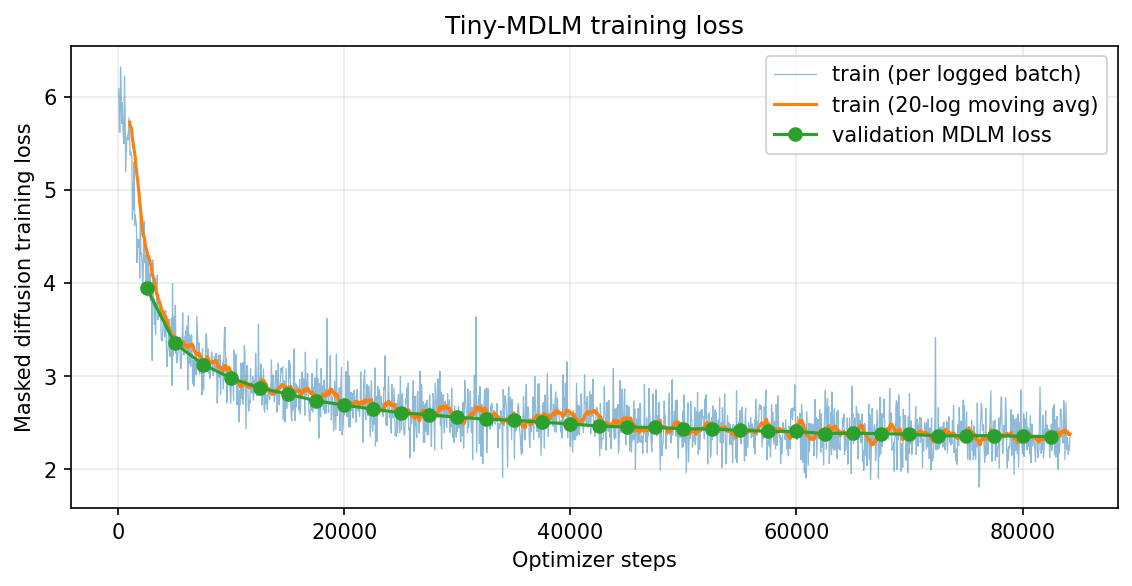

The loss decreases clearly. Training loss falls from ≈ 6 at the start to ≈ 4 after 2.5k steps (the model first learns frequent words), then more slowly to ≈ 2.4 at the end. The curve is noisy because every batch draws new masking ratios t, and batches with small t get a large 1/t weight. The held-out validation MDLM loss (fixed seed) decreases monotonically: 3.95 (step 2.5k) → 2.87 (12.5k) → 2.65 (22.5k) → 2.54 (32.5k) → 2.47 (42.5k) → 2.43 (52.5k) → 2.38 (62.5k) → 2.36 (72.5k) → 2.35 (82.5k), and is 2.33 at the end. It flattens in the last ≈ 15k steps but never rises. The final validation loss (2.33) is not higher than the training loss (2.38), so **no overfitting is evident** after 20 epochs. Random re-masking acts as strong data augmentation (each block is seen with a different mask every epoch); the flattening indicates the 14M model is approaching its capacity for this budget rather than memorising the training set.

## Q3 — Evaluation and analysis

**(a) Masked cross-entropy on the full validation set** (all 2,061 validation blocks, same fixed-seed masks for each ratio)

| Masking ratio | MCE (nats) ↓ | Masked-token accuracy |
|---|---|---|
| 25% | 1.160 | 72.2% |
| 50% | 1.849 | 59.2% |
| 75% | 3.156 | 37.8% |

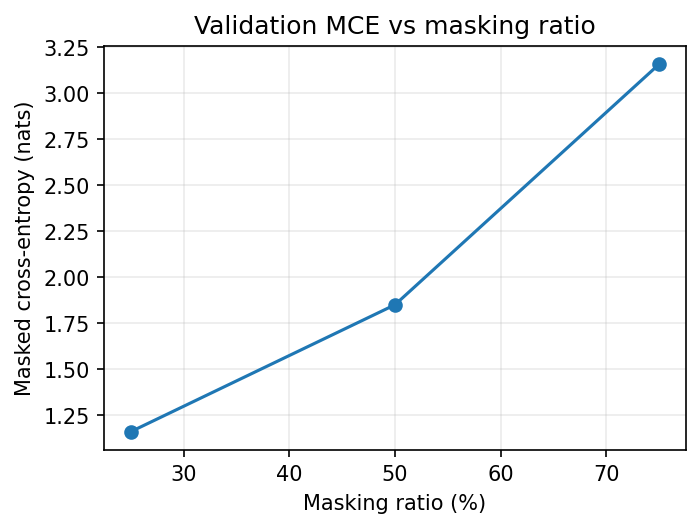

MCE increases monotonically and faster than linearly with the masking ratio (+0.69 nats from 25%→50%, +1.31 nats from 50%→75%), and accuracy drops from 72% to 38%. With 25% masking most of the context is visible on both sides of each masked token, so the bidirectional model can often infer it almost deterministically (function words, punctuation, repeated character names such as "Lily"). At 75% masking the remaining context is sparse, many continuations are plausible, and the prediction approaches an unconditional language-model guess, so the per-token uncertainty is much higher. MCE is a reconstruction metric at a fixed ratio, not an autoregressive perplexity (exp(MCE) is not reported as PPL).

**(b) Generation with 4 / 8 / 16 steps** (prompt "Once upon a time", 64 tokens, greedy confidence-based unmasking; decoding times are means of 5 runs after a warm-up, with CUDA synchronisation)

| Steps | Decoding time | distinct-1 / distinct-2 | Generated text |
|---|---|---|---|
| 4 | 14.8 ms | 0.79 / 0.95 | Once upon a time, there was a little girl named Lily. She loved to play with her her toy bear...,,, she went to school and and saw with..... with the together..... They They played laughed and and and had fun together. The end. |
| 8 | 30.3 ms | 0.77 / 0.98 | Once upon a time, there was a little girl named Lily. She loved to play with her toys and day.. One day, she's mom came in visit room room. She saw Lily playing and and. Lily Lily Lily was happy. She They her back and and played with it together. The end. |
| 16 | 61.2 ms | 0.83 / 1.00 | Once upon a time, there was a little girl named Lily. She loved to play with her toys and especially candy, especially. One One, day Lily's mom told her to be to the park and play more. But Lily was't want to because she she wanted to eat more candy candy. The end. |

**Speed.** Decoding time is almost exactly proportional to the number of steps (14.8 → 30.3 → 61.2 ms, about 3.8 ms per step), because every step is one full forward pass over the 64-token sequence.

**Fluency and repetition.** All three settings produce the typical TinyStories frame ("…a little girl named Lily…", "…The end."), because the first and last tokens are very predictable and are revealed first.
* **4 steps** (~15 tokens revealed per step) is the least fluent. Tokens committed in the same step are predicted independently from the same context, so they cannot coordinate: punctuation runs ("...,,,", "....."), adjacent duplicates ("her her", "and and and", "They They"), and almost no story content.
* **8 steps** is somewhat better ("One day, she's mom came in visit room"), but repetition remains ("room room", "Lily Lily Lily").
* **16 steps** gives the most coherent story, with a small plot (mom tells Lily to go to the park; she wants to eat more candy), the highest lexical diversity (distinct-1 0.83, distinct-2 1.00), no punctuation runs, and fewer duplicates ("One One", "she she", "candy candy").

More steps trade speed for quality: each token is conditioned on more already-revealed neighbours, which reduces independent, conflicting predictions.

## Q4 — Questions

**(a) MDLM vs. autoregressive generation.** An autoregressive model generates strictly left-to-right, one token per forward pass, each conditioned only on the prefix (causal attention); generating n tokens needs n sequential steps. An MDLM starts from a fully masked suffix and uses a bidirectional Transformer to predict all masked positions in parallel; at each step it commits a subset (here, the most confident ones) in any order, and later steps condition on tokens on both sides. The number of steps is a free speed/quality knob (it can be far smaller than the length), committed tokens are never revised in this sampler, and tokens revealed in the same step are sampled independently (the factorisation error that causes incoherence with few steps).

**(b) Why different masking ratios during training?** At generation time the model must denoise every noise level — from a fully masked suffix (t ≈ 1) to an almost finished sequence (t ≈ 0). Sampling t ~ U(0,1) trains a single network for all these states, and the 1/t-weighted loss is (an upper bound related to) the negative ELBO of the diffusion process integrated over t. It also acts as data augmentation: the same story yields many different prediction tasks, from almost-unconditional generation to near-trivial cloze filling.

**(c) Why can a low reconstruction loss still give repetitive/incoherent text?** The loss measures *per-token marginal* predictions given a context that comes from real data. During generation (i) many tokens are revealed in the same step, each from its own marginal, so the joint sample can be inconsistent (e.g. two positions both choose the most likely word → repetition); (ii) the model conditions on its own earlier predictions, which are off the training distribution, so errors compound; (iii) greedy max-confidence selection favours frequent, "safe" tokens (the, and, ., names), which creates loops; and (iv) low MCE is dominated by easy, locally predictable tokens and says little about global coherence over 64 tokens. More steps, temperature/top-p sampling or remasking strategies mitigate this.
